Máxima densidad en toda la animación: 0.644724730691102


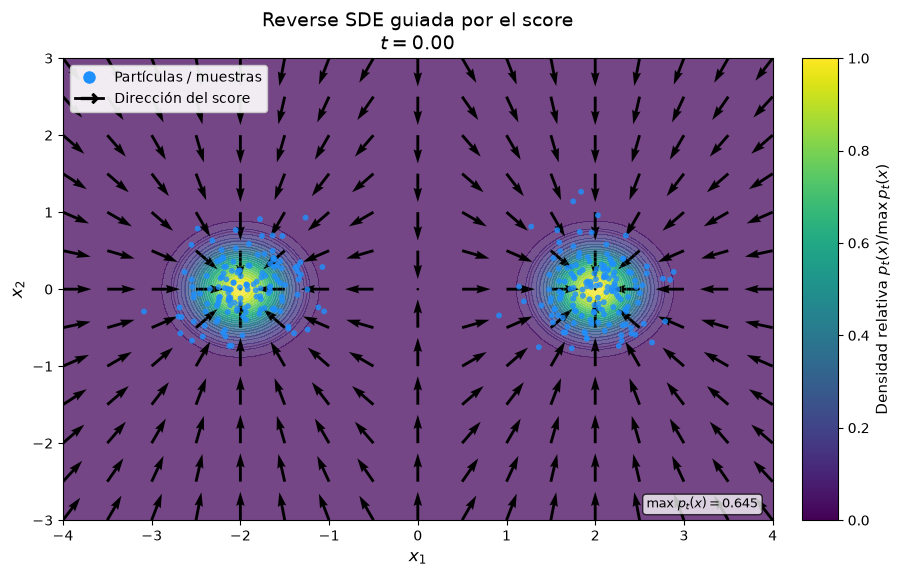

In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F

import numpy as np
import matplotlib.pyplot as plt
import math
import numpy as np

%run "Score en 2D.ipynb"

Dispositivo

In [21]:
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Dispositivo:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

Dispositivo: cuda
GPU: Quadro RTX 6000


PARÁMETROS DE LA MEZCLA BIMODAL

In [22]:
sigma0 = 0.35

means_torch = torch.tensor(
    [
        [-2.0, 0.0],
        [ 2.0, 0.0]
    ],
    dtype=torch.float32,
    device=device
)

weights_torch = torch.tensor(
    [0.5, 0.5],
    dtype=torch.float32,
    device=device
)
    

VP-SDE

In [23]:
beta_min = 0.1
beta_max = 12.0


def beta_torch(t):
    return beta_min + (beta_max - beta_min) * t


def integral_beta_torch(t):

    return (
        beta_min * t
        +
        0.5 * (beta_max - beta_min) * t**2
    )


def alpha_bar_torch(t):

    return torch.exp(
        -integral_beta_torch(t)
    )

### MUESTREAR DE \(p_0(x)\)

Aquí generamos muestras de la distribución original \(p_0(x)\), escogemos un \(t\) aleatorio y aplicamos el proceso forward:

$$
x_t = \sqrt{\bar{\alpha}(t)}\,x_0
+ \sqrt{1-\bar{\alpha}(t)}\,\epsilon
$$

In [24]:
def sample_p0(batch_size):

    # Elegir aleatoriamente uno de los dos modos
    components = torch.randint(
        0,
        2,
        (batch_size,),
        device=device
    )

    selected_means = means_torch[
        components
    ]

    noise = torch.randn(
        batch_size,
        2,
        device=device
    )

    x0 = (
        selected_means
        +
        sigma0 * noise
    )

    return x0

APLICAR FORWARD SDE

In [25]:
def sample_xt(x0, t):

    """
    x0: [B,2]
    t:  [B]
    """

    abar = alpha_bar_torch(t)

    abar = abar[:, None]

    epsilon = torch.randn_like(
        x0
    )

    xt = (
        torch.sqrt(abar) * x0
        +
        torch.sqrt(1.0 - abar) * epsilon
    )

    return xt, epsilon

### SCORE ANALÍTICO DE LA MEZCLA

Esta es la función que la red deberá aprender:

$$
s(x,t) = \nabla_x \log {p_t} (x)
$$

In [26]:
def exact_score_torch(x, t):

    """
    x: [B,2]
    t: [B]

    return:
        score exacto [B,2]
    """

    abar = alpha_bar_torch(t)

    # ------------------------------------------
    # Media de cada componente en tiempo t
    # ------------------------------------------

    means_current = (
        torch.sqrt(abar)[:, None, None]
        *
        means_torch[None, :, :]
    )

    # ------------------------------------------
    # Varianza de cada componente en tiempo t
    # ------------------------------------------

    variance = (
        abar * sigma0**2
        +
        (1.0 - abar)
    )

    # x: [B,1,2]
    x_expanded = x[:, None, :]

    # diferencia respecto a cada modo
    diff = (
        x_expanded
        -
        means_current
    )

    # ------------------------------------------
    # log p_i(x,t)
    # ------------------------------------------

    log_components = (

        -0.5
        *
        torch.sum(
            diff**2,
            dim=-1
        )
        /
        variance[:, None]

        -

        torch.log(
            2.0
            *
            torch.tensor(
                math.pi,
                device=device
            )
            *
            variance[:, None]
        )

        +

        torch.log(
            weights_torch[None, :]
        )
    )

    # ------------------------------------------
    # Responsabilidad de cada componente
    # ------------------------------------------

    responsibilities = torch.softmax(
        log_components,
        dim=1
    )

    # ------------------------------------------
    # Score individual de cada gaussiana
    # ------------------------------------------

    component_scores = (
        -diff
        /
        variance[:, None, None]
    )

    # ------------------------------------------
    # Score total de la mezcla
    # ------------------------------------------

    score = torch.sum(

        responsibilities[:, :, None]
        *
        component_scores,

        dim=1
    )

    return score

TIME EMBEDDING

In [27]:
class SinusoidalTimeEmbedding(nn.Module):

    def __init__(self, dim=32):

        super().__init__()

        self.dim = dim


    def forward(self, t):

        half_dim = self.dim // 2

        frequencies = torch.exp(

            torch.linspace(
                0,
                -math.log(10000),
                half_dim,
                device=t.device
            )

        )

        angles = (
            t[:, None]
            *
            frequencies[None, :]
            *
            1000
        )

        embedding = torch.cat(
            [
                torch.sin(angles),
                torch.cos(angles)
            ],
            dim=1
        )

        return embedding

RED PARA APRENDER EL SCORE

In [28]:
class ScoreNetwork(nn.Module):

    def __init__(
        self,
        time_dim=32,
        hidden_dim=128
    ):

        super().__init__()

        self.time_embedding = nn.Sequential(

            SinusoidalTimeEmbedding(
                time_dim
            ),

            nn.Linear(
                time_dim,
                time_dim
            ),

            nn.SiLU(),

            nn.Linear(
                time_dim,
                time_dim
            )
        )


        self.network = nn.Sequential(

            nn.Linear(
                2 + time_dim,
                hidden_dim
            ),

            nn.SiLU(),

            nn.Linear(
                hidden_dim,
                hidden_dim
            ),

            nn.SiLU(),

            nn.Linear(
                hidden_dim,
                hidden_dim
            ),

            nn.SiLU(),

            nn.Linear(
                hidden_dim,
                2
            )
        )


    def forward(self, x, t):

        t_emb = self.time_embedding(
            t
        )

        h = torch.cat(
            [
                x,
                t_emb
            ],
            dim=1
        )

        return self.network(h)


model_score = ScoreNetwork().to(
    device
)

print(model_score)

ScoreNetwork(
  (time_embedding): Sequential(
    (0): SinusoidalTimeEmbedding()
    (1): Linear(in_features=32, out_features=32, bias=True)
    (2): SiLU()
    (3): Linear(in_features=32, out_features=32, bias=True)
  )
  (network): Sequential(
    (0): Linear(in_features=34, out_features=128, bias=True)
    (1): SiLU()
    (2): Linear(in_features=128, out_features=128, bias=True)
    (3): SiLU()
    (4): Linear(in_features=128, out_features=128, bias=True)
    (5): SiLU()
    (6): Linear(in_features=128, out_features=2, bias=True)
  )
)


ENTRENAMIENTO

In [29]:
optimizer = torch.optim.Adam(
    model_score.parameters(),
    lr=1e-3
)


n_steps_training = 5000
batch_size = 2048

loss_history = []


model_score.train()


for step in range(
    n_steps_training
):

    # ------------------------------------------
    # 1. Muestra x0
    # ------------------------------------------

    x0 = sample_p0(
        batch_size
    )


    # ------------------------------------------
    # 2. Tiempo aleatorio
    #
    # Evitamos exactamente t=0 por estabilidad
    # ------------------------------------------

    t = (
        0.001
        +
        0.999
        *
        torch.rand(
            batch_size,
            device=device
        )
    )


    # ------------------------------------------
    # 3. Forward
    # ------------------------------------------

    xt, _ = sample_xt(
        x0,
        t
    )


    # ------------------------------------------
    # 4. Score exacto
    # ------------------------------------------

    with torch.no_grad():

        target_score = exact_score_torch(
            xt,
            t
        )


    # ------------------------------------------
    # 5. Score predicho
    # ------------------------------------------

    predicted_score = model_score(
        xt,
        t
    )


    # ------------------------------------------
    # 6. Loss
    # ------------------------------------------

    loss = F.mse_loss(
        predicted_score,
        target_score
    )


    # ------------------------------------------
    # 7. Backpropagation
    # ------------------------------------------

    optimizer.zero_grad()

    loss.backward()

    optimizer.step()


    loss_history.append(
        loss.item()
    )


    # ------------------------------------------
    # Mostrar progreso
    # ------------------------------------------

    if step % 250 == 0:

        print(
            f"Step {step:5d}"
            f" | Loss: {loss.item():.6f}"
        )

Step     0 | Loss: 2.034741


Step   250 | Loss: 0.059168
Step   500 | Loss: 0.008534
Step   750 | Loss: 0.004845
Step  1000 | Loss: 0.008426
Step  1250 | Loss: 0.005829
Step  1500 | Loss: 0.005788
Step  1750 | Loss: 0.001941
Step  2000 | Loss: 0.001547
Step  2250 | Loss: 0.009280
Step  2500 | Loss: 0.003909
Step  2750 | Loss: 0.001484
Step  3000 | Loss: 0.001512
Step  3250 | Loss: 0.000616
Step  3500 | Loss: 0.001462
Step  3750 | Loss: 0.013709
Step  4000 | Loss: 0.000706
Step  4250 | Loss: 0.000658
Step  4500 | Loss: 0.000913
Step  4750 | Loss: 0.004853


CURVA DE ENTRENAMIENTO

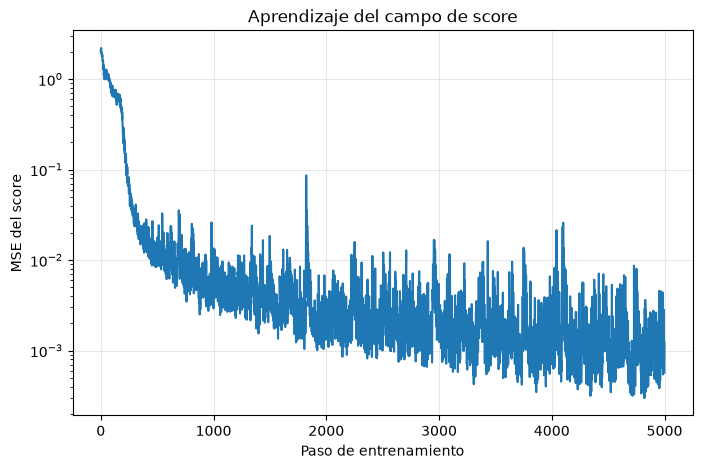

In [30]:
plt.figure(
    figsize=(8, 5)
)

plt.plot(
    loss_history
)

plt.xlabel(
    "Paso de entrenamiento"
)

plt.ylabel(
    "MSE del score"
)

plt.title(
    "Aprendizaje del campo de score"
)

plt.yscale(
    "log"
)

plt.grid(
    alpha=0.3
)

plt.show()

CURVA DE PÉRDIDA SUAVIZADA

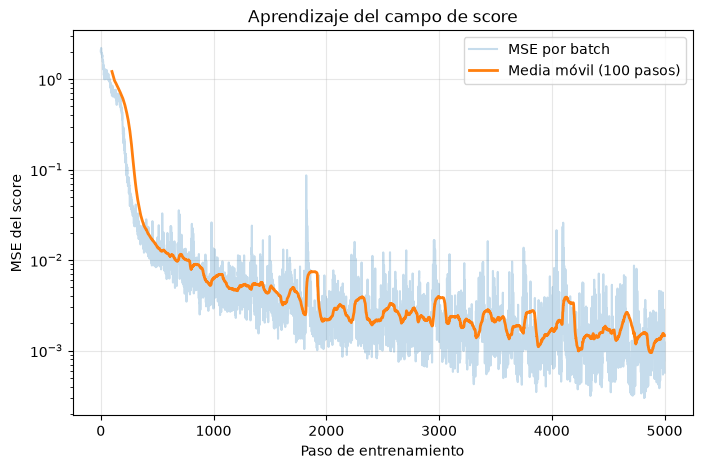

In [31]:
loss_array = np.array(loss_history)

window = 100

moving_average = np.convolve(
    loss_array,
    np.ones(window) / window,
    mode="valid"
)

plt.figure(figsize=(8, 5))

# Loss original
plt.plot(
    loss_array,
    alpha=0.25,
    label="MSE por batch"
)

# Media móvil
plt.plot(
    np.arange(window - 1, len(loss_array)),
    moving_average,
    linewidth=2,
    label=f"Media móvil ({window} pasos)"
)

plt.xlabel("Paso de entrenamiento")
plt.ylabel("MSE del score")

plt.title(
    "Aprendizaje del campo de score"
)

plt.yscale("log")

plt.grid(
    alpha=0.3
)

plt.legend()

plt.show()

COMPARAR SCORE EXACTO VS APRENDIDO

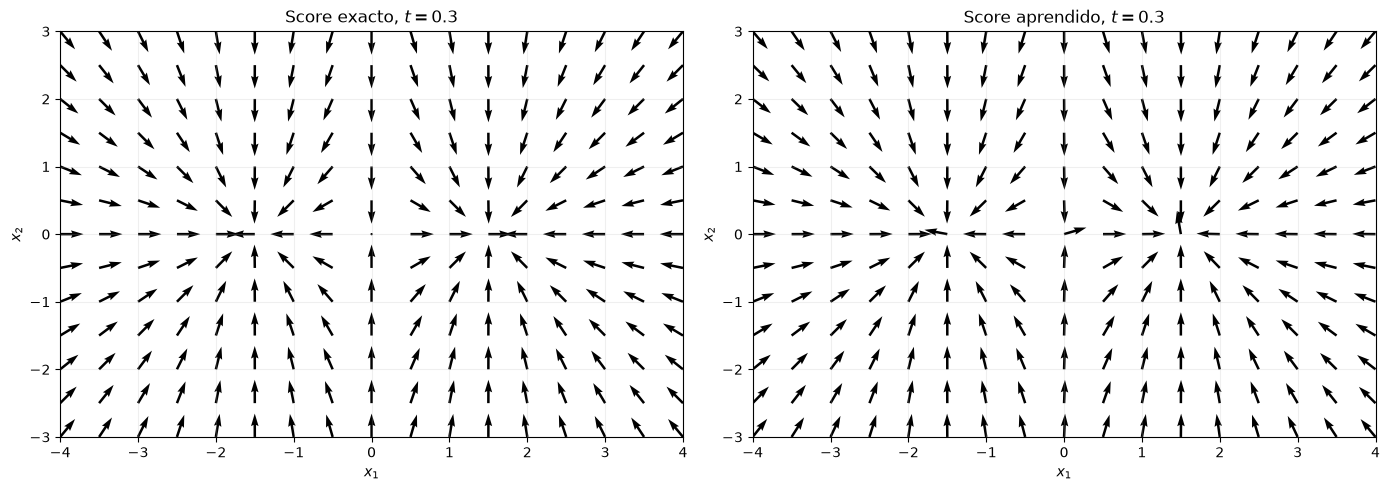

In [32]:
model_score.eval()

t_test = 0.30


# ------------------------------------------------------------
# Grid
# ------------------------------------------------------------

qx = np.linspace(
    -4,
    4,
    17
)

qy = np.linspace(
    -3,
    3,
    13
)

QX, QY = np.meshgrid(
    qx,
    qy
)


points_numpy = np.stack(
    [
        QX.ravel(),
        QY.ravel()
    ],
    axis=1
)


points = torch.tensor(
    points_numpy,
    dtype=torch.float32,
    device=device
)


times_test = torch.full(
    (
        points.shape[0],
    ),
    t_test,
    device=device
)


# ------------------------------------------------------------
# Score exacto
# ------------------------------------------------------------

with torch.no_grad():

    exact = exact_score_torch(
        points,
        times_test
    )

    learned = model_score(
        points,
        times_test
    )


exact = exact.cpu().numpy()

learned = learned.cpu().numpy()


# ------------------------------------------------------------
# Normalizar SOLO para visualizar dirección
# ------------------------------------------------------------

exact_norm = np.linalg.norm(
    exact,
    axis=1,
    keepdims=True
)

learned_norm = np.linalg.norm(
    learned,
    axis=1,
    keepdims=True
)


exact_direction = (
    exact
    /
    (exact_norm + 1e-8)
)


learned_direction = (
    learned
    /
    (learned_norm + 1e-8)
)


# Volver a forma del grid
exact_direction = exact_direction.reshape(
    QX.shape + (2,)
)

learned_direction = learned_direction.reshape(
    QX.shape + (2,)
)


# ============================================================
# GRÁFICAS
# ============================================================

fig, axes = plt.subplots(
    1,
    2,
    figsize=(14, 5)
)


# ------------------------------------------------------------
# Score exacto
# ------------------------------------------------------------

axes[0].quiver(

    QX,
    QY,

    exact_direction[..., 0],
    exact_direction[..., 1],

    color="black"
)

axes[0].set_title(
    rf"Score exacto, $t={t_test}$"
)


# ------------------------------------------------------------
# Score aprendido
# ------------------------------------------------------------

axes[1].quiver(

    QX,
    QY,

    learned_direction[..., 0],
    learned_direction[..., 1],

    color="black"
)

axes[1].set_title(
    rf"Score aprendido, $t={t_test}$"
)


# ------------------------------------------------------------
# Formato
# ------------------------------------------------------------

for ax in axes:

    ax.set_xlim(
        -4,
        4
    )

    ax.set_ylim(
        -3,
        3
    )

    ax.set_xlabel(
        r"$x_1$"
    )

    ax.set_ylabel(
        r"$x_2$"
    )

    ax.grid(
        alpha=0.2
    )


plt.tight_layout()

plt.show()

MAPA DE ERROR DEL SCORE

MSE del score: 6.463809e-03
Error vectorial promedio: 8.207260e-02
Error vectorial máximo: 5.143779e-01


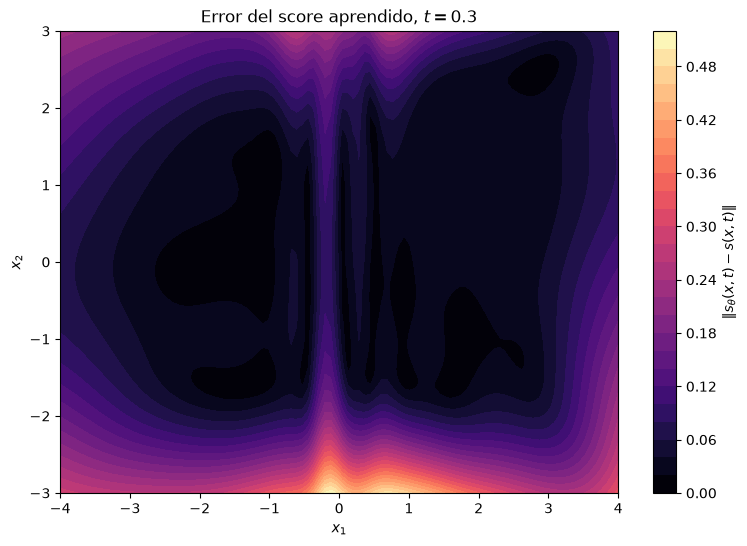

In [33]:
model_score.eval()

t_test = 0.30


# ------------------------------------------------------------
# Grid más fino para evaluar el error
# ------------------------------------------------------------

x_values = np.linspace(
    -4,
    4,
    100
)

y_values = np.linspace(
    -3,
    3,
    80
)

XX_error, YY_error = np.meshgrid(
    x_values,
    y_values
)

points_numpy = np.stack(
    [
        XX_error.ravel(),
        YY_error.ravel()
    ],
    axis=1
)

points = torch.tensor(
    points_numpy,
    dtype=torch.float32,
    device=device
)

times_test = torch.full(
    (points.shape[0],),
    t_test,
    device=device
)


# ------------------------------------------------------------
# Score exacto y aprendido
# ------------------------------------------------------------

with torch.no_grad():

    exact_score = exact_score_torch(
        points,
        times_test
    )

    learned_score = model_score(
        points,
        times_test
    )


# ------------------------------------------------------------
# Error vectorial
# ------------------------------------------------------------

error_vector = (
    learned_score
    -
    exact_score
)

error_norm = torch.linalg.norm(
    error_vector,
    dim=1
)


# ------------------------------------------------------------
# Métricas globales
# ------------------------------------------------------------

mse_score = torch.mean(
    error_vector**2
).item()

mean_vector_error = torch.mean(
    error_norm
).item()

max_vector_error = torch.max(
    error_norm
).item()


print(
    f"MSE del score: {mse_score:.6e}"
)

print(
    f"Error vectorial promedio: {mean_vector_error:.6e}"
)

print(
    f"Error vectorial máximo: {max_vector_error:.6e}"
)


# ------------------------------------------------------------
# Convertir a numpy y reconstruir grid
# ------------------------------------------------------------

error_map = error_norm.cpu().numpy().reshape(
    XX_error.shape
)


# ============================================================
# GRÁFICA
# ============================================================

plt.figure(
    figsize=(9, 6)
)

contour = plt.contourf(
    XX_error,
    YY_error,
    error_map,
    levels=30,
    cmap="magma"
)

cbar = plt.colorbar(
    contour
)

cbar.set_label(
    r"$\|s_\theta(x,t)-s(x,t)\|$"
)

plt.xlabel(
    r"$x_1$"
)

plt.ylabel(
    r"$x_2$"
)

plt.title(
    rf"Error del score aprendido, $t={t_test}$"
)

plt.show()

MAPA DE ERROR EN REGIONES RELEVANTES

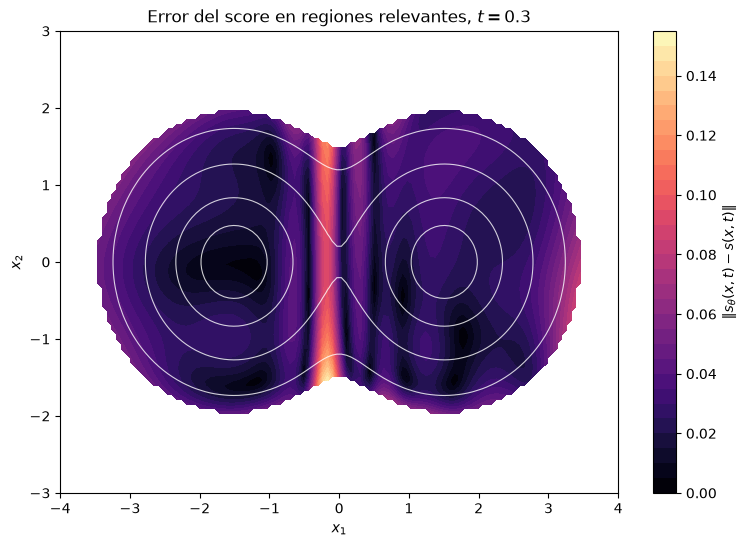

In [34]:
model_score.eval()

t_test = 0.30


# ------------------------------------------------------------
# Grid
# ------------------------------------------------------------

x_values = np.linspace(-4, 4, 120)
y_values = np.linspace(-3, 3, 100)

XX_error, YY_error = np.meshgrid(
    x_values,
    y_values
)

points_numpy = np.stack(
    [
        XX_error.ravel(),
        YY_error.ravel()
    ],
    axis=1
)

points = torch.tensor(
    points_numpy,
    dtype=torch.float32,
    device=device
)

times_test = torch.full(
    (points.shape[0],),
    t_test,
    device=device
)


# ------------------------------------------------------------
# Score exacto y aprendido
# ------------------------------------------------------------

with torch.no_grad():

    exact_score = exact_score_torch(
        points,
        times_test
    )

    learned_score = model_score(
        points,
        times_test
    )


# ------------------------------------------------------------
# Error vectorial
# ------------------------------------------------------------

error_vector = (
    learned_score
    -
    exact_score
)

error_norm = torch.linalg.norm(
    error_vector,
    dim=1
)

error_map = error_norm.cpu().numpy().reshape(
    XX_error.shape
)


# ============================================================
# DENSIDAD p_t(x)
# ============================================================

grid_points_error = np.stack(
    [
        XX_error,
        YY_error
    ],
    axis=-1
)

density = density_mixture(
    grid_points_error,
    t_test
)

density_relative = (
    density
    /
    np.max(density)
)


# ============================================================
# ENMASCARAR REGIONES DE MUY BAJA DENSIDAD
# ============================================================

threshold = 0.02

masked_error = np.ma.masked_where(
    density_relative < threshold,
    error_map
)


# ============================================================
# GRÁFICA
# ============================================================

plt.figure(
    figsize=(9, 6)
)

contour = plt.contourf(
    XX_error,
    YY_error,
    masked_error,
    levels=30,
    cmap="magma"
)

cbar = plt.colorbar(
    contour
)

cbar.set_label(
    r"$\|s_\theta(x,t)-s(x,t)\|$"
)


# ------------------------------------------------------------
# Curvas de densidad para dar contexto
# ------------------------------------------------------------

plt.contour(
    XX_error,
    YY_error,
    density_relative,
    levels=[0.05, 0.2, 0.5, 0.8],
    colors="white",
    linewidths=0.8,
    alpha=0.8
)


plt.xlabel(
    r"$x_1$"
)

plt.ylabel(
    r"$x_2$"
)

plt.title(
    rf"Error del score en regiones relevantes, $t={t_test}$"
)

plt.show()

SIMILITUD DE DIRECCIÓN

In [35]:
epsilon_small = 1e-8

dot_product = torch.sum(
    exact_score * learned_score,
    dim=1
)

exact_norm = torch.linalg.norm(
    exact_score,
    dim=1
)

learned_norm = torch.linalg.norm(
    learned_score,
    dim=1
)

cosine_similarity = (
    dot_product
    /
    (
        exact_norm
        *
        learned_norm
        +
        epsilon_small
    )
)


mean_cosine_similarity = torch.mean(
    cosine_similarity
).item()


print(
    "Similitud coseno promedio:",
    mean_cosine_similarity
)

Similitud coseno promedio: 0.999900221824646


ERROR DEL SCORE EN FUNCIÓN DEL TIEMPO

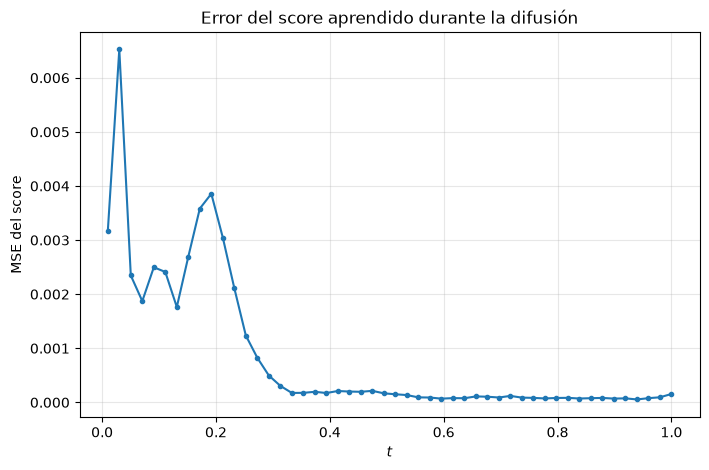

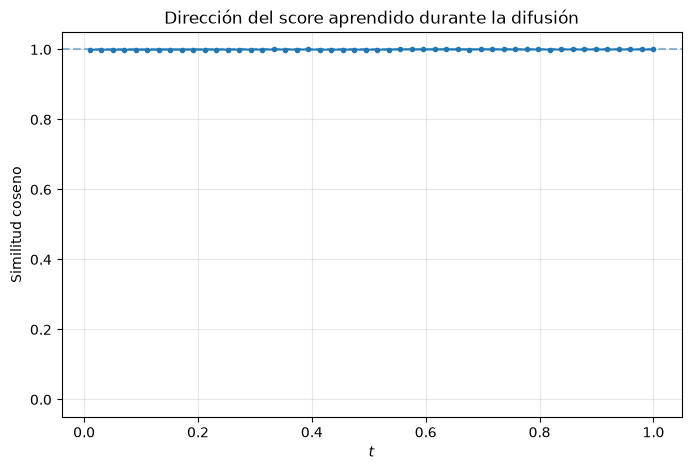

In [36]:
model_score.eval()

# Valores de t donde evaluaremos
t_values = np.linspace(
    0.01,
    1.0,
    50
)

# Número de muestras utilizadas en cada t
n_eval = 10000

mse_vs_t = []
vector_error_vs_t = []
cosine_vs_t = []


for t_value in t_values:

    # --------------------------------------------------------
    # 1. Generar muestras de p_0
    # --------------------------------------------------------

    x0 = sample_p0(
        n_eval
    )


    # --------------------------------------------------------
    # 2. Crear un tensor con el mismo t para todas las muestras
    # --------------------------------------------------------

    t_batch = torch.full(
        (n_eval,),
        float(t_value),
        device=device
    )


    # --------------------------------------------------------
    # 3. Generar x_t mediante el forward
    # --------------------------------------------------------

    xt, _ = sample_xt(
        x0,
        t_batch
    )


    # --------------------------------------------------------
    # 4. Score exacto y aprendido
    # --------------------------------------------------------

    with torch.no_grad():

        exact_score = exact_score_torch(
            xt,
            t_batch
        )

        learned_score = model_score(
            xt,
            t_batch
        )


    # ========================================================
    # 5. ERROR MSE
    # ========================================================

    mse = torch.mean(
        (learned_score - exact_score)**2
    )

    mse_vs_t.append(
        mse.item()
    )


    # ========================================================
    # 6. ERROR VECTORIAL PROMEDIO
    # ========================================================

    vector_error = torch.linalg.norm(
        learned_score - exact_score,
        dim=1
    )

    vector_error_vs_t.append(
        vector_error.mean().item()
    )


    # ========================================================
    # 7. SIMILITUD DE DIRECCIÓN
    # ========================================================

    dot_product = torch.sum(
        exact_score * learned_score,
        dim=1
    )

    exact_norm = torch.linalg.norm(
        exact_score,
        dim=1
    )

    learned_norm = torch.linalg.norm(
        learned_score,
        dim=1
    )

    cosine_similarity = (
        dot_product
        /
        (
            exact_norm
            *
            learned_norm
            +
            1e-8
        )
    )

    cosine_vs_t.append(
        cosine_similarity.mean().item()
    )


# ============================================================
# GRÁFICA 1: MSE VS t
# ============================================================

plt.figure(
    figsize=(8, 5)
)

plt.plot(
    t_values,
    mse_vs_t,
    marker="o",
    markersize=3
)

plt.xlabel(
    r"$t$"
)

plt.ylabel(
    "MSE del score"
)

plt.title(
    "Error del score aprendido durante la difusión"
)

plt.grid(
    alpha=0.3
)

plt.show()


# ============================================================
# GRÁFICA 2: SIMILITUD DE DIRECCIÓN VS t
# ============================================================

plt.figure(
    figsize=(8, 5)
)

plt.plot(
    t_values,
    cosine_vs_t,
    marker="o",
    markersize=3
)

plt.axhline(
    1.0,
    linestyle="--",
    alpha=0.5
)

plt.xlabel(
    r"$t$"
)

plt.ylabel(
    "Similitud coseno"
)

plt.title(
    "Dirección del score aprendido durante la difusión"
)

plt.ylim(
    -0.05,
    1.05
)

plt.grid(
    alpha=0.3
)

plt.show()

REVERSE SDE USANDO EL SCORE APRENDIDO

In [37]:
model_score.eval()

rng_learned = np.random.default_rng(7)

n_particles = 300
n_steps_reverse = 300

times_reverse = np.linspace(
    1.0,
    0.0,
    n_steps_reverse
)

h = 1.0 / (n_steps_reverse - 1)


# ============================================================
# ESTADO INICIAL: PRIOR N(0,I)
# ============================================================

x_learned = rng_learned.normal(
    size=(n_particles, 2)
)

trajectory_learned = [
    x_learned.copy()
]


# ============================================================
# INTEGRACIÓN DE LA REVERSE SDE
# ============================================================

for t_value in times_reverse[:-1]:

    beta_value = beta(t_value)


    # --------------------------------------------------------
    # Convertir partículas a tensor
    # --------------------------------------------------------

    x_tensor = torch.tensor(
        x_learned,
        dtype=torch.float32,
        device=device
    )


    t_tensor = torch.full(
        (n_particles,),
        float(t_value),
        dtype=torch.float32,
        device=device
    )


    # --------------------------------------------------------
    # SCORE APRENDIDO
    # --------------------------------------------------------

    with torch.no_grad():

        learned_score = model_score(
            x_tensor,
            t_tensor
        )


    learned_score = (
        learned_score
        .cpu()
        .numpy()
    )


    # --------------------------------------------------------
    # Drift de la reverse SDE
    #
    # -f + g² s_theta
    #
    # con
    #
    # f = -1/2 beta x
    # g² = beta
    # --------------------------------------------------------

    reverse_drift = (

        0.5
        *
        beta_value
        *
        x_learned

        +

        beta_value
        *
        learned_score
    )


    # --------------------------------------------------------
    # Ruido estocástico
    # --------------------------------------------------------

    noise = rng_learned.normal(
        size=x_learned.shape
    )


    # --------------------------------------------------------
    # Euler-Maruyama
    # --------------------------------------------------------

    x_learned = (

        x_learned

        +

        reverse_drift
        *
        h

        +

        np.sqrt(
            beta_value * h
        )
        *
        noise
    )


    trajectory_learned.append(
        x_learned.copy()
    )


trajectory_learned = np.array(
    trajectory_learned
)


print(
    "Simulación con score aprendido terminada."
)

Simulación con score aprendido terminada.


DISTRIBUCIÓN FINAL GENERADA

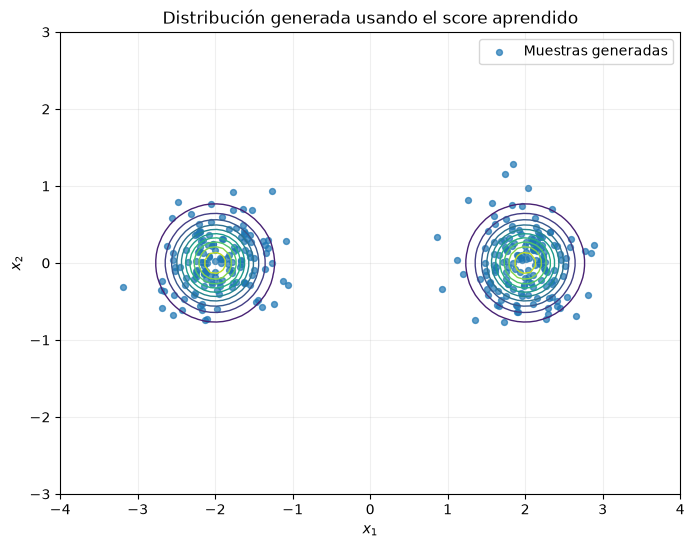

In [39]:
final_samples = trajectory_learned[-1]

plt.figure(
    figsize=(8, 6)
)


# ------------------------------------------------------------
# Densidad objetivo p_0
# ------------------------------------------------------------

density_target = density_mixture(
    grid_points,
    0.0
)

plt.contour(
    XX,
    YY,
    density_target,
    levels=10,
    linewidths=1
)


# ------------------------------------------------------------
# Muestras generadas
# ------------------------------------------------------------

plt.scatter(
    final_samples[:, 0],
    final_samples[:, 1],
    s=18,
    alpha=0.7,
    label="Muestras generadas"
)


plt.xlabel(
    r"$x_1$"
)

plt.ylabel(
    r"$x_2$"
)

plt.title(
    "Distribución generada usando el score aprendido"
)

plt.xlim(
    -4,
    4
)

plt.ylim(
    -3,
    3
)

plt.legend()

plt.grid(
    alpha=0.2
)

plt.show()

COMPARATIVA

Simulación exacta y aprendida terminada.


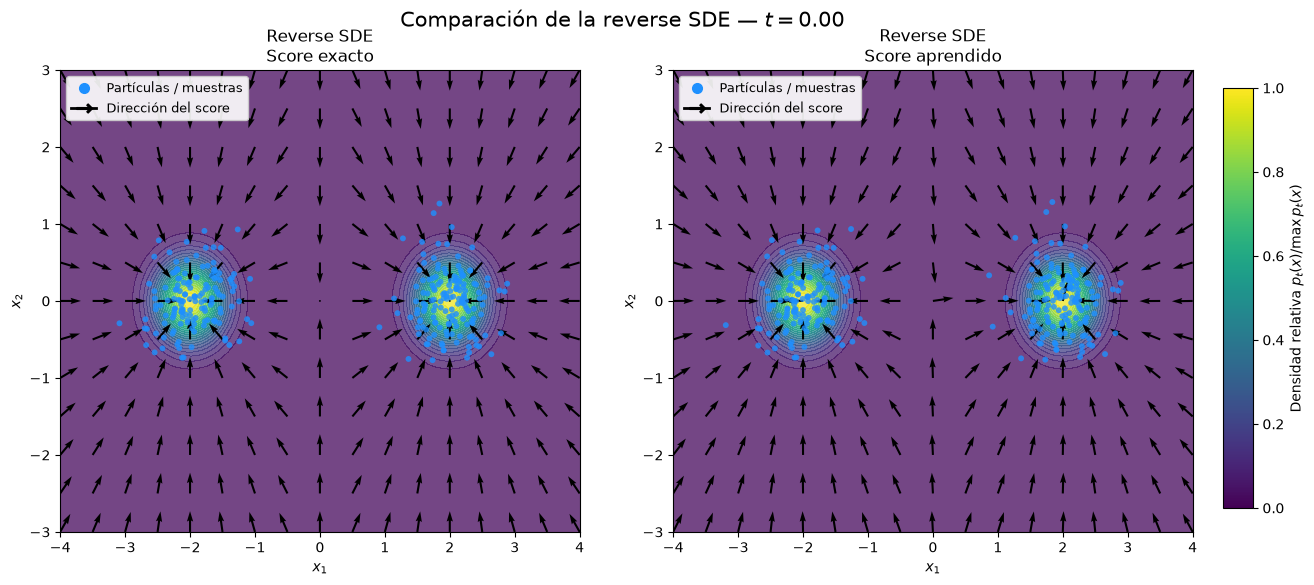

In [40]:
# ============================================================
# 1. FUNCIÓN PARA OBTENER EL SCORE APRENDIDO EN NUMPY
# ============================================================

def learned_score_numpy(x, t):

    """
    x: array numpy [N, 2]
    t: escalar
    """

    x_tensor = torch.tensor(
        x,
        dtype=torch.float32,
        device=device
    )

    t_tensor = torch.full(
        (x.shape[0],),
        float(t),
        dtype=torch.float32,
        device=device
    )

    model_score.eval()

    with torch.no_grad():

        score = model_score(
            x_tensor,
            t_tensor
        )

    return score.cpu().numpy()


# ============================================================
# 2. PARÁMETROS DE LA SIMULACIÓN
# ============================================================

n_particles = 300
n_steps = 300

times_compare = np.linspace(
    1.0,
    0.0,
    n_steps
)

h = 1.0 / (n_steps - 1)

rng_compare = np.random.default_rng(7)


# ============================================================
# 3. MISMAS PARTÍCULAS INICIALES PARA AMBOS MÉTODOS
#
# x_T ~ N(0,I)
# ============================================================

initial_particles = rng_compare.normal(
    size=(n_particles, 2)
)

x_exact = initial_particles.copy()
x_learned = initial_particles.copy()


trajectory_exact = [
    x_exact.copy()
]

trajectory_learned = [
    x_learned.copy()
]


# ============================================================
# 4. SIMULAR AMBAS REVERSE SDE
#
# IMPORTANTE:
# usamos exactamente el MISMO ruido z en ambos procesos.
# ============================================================

for t_value in times_compare[:-1]:

    beta_value = beta(
        t_value
    )


    # --------------------------------------------------------
    # SCORE EXACTO
    # --------------------------------------------------------

    score_exact = score_mixture(
        x_exact,
        t_value
    )


    # --------------------------------------------------------
    # SCORE APRENDIDO
    # --------------------------------------------------------

    score_learned = learned_score_numpy(
        x_learned,
        t_value
    )


    # --------------------------------------------------------
    # DRIFT INVERSO
    #
    # -f + g² s
    #
    # f = -1/2 beta x
    # g² = beta
    # --------------------------------------------------------

    drift_exact = (
        0.5
        *
        beta_value
        *
        x_exact

        +

        beta_value
        *
        score_exact
    )


    drift_learned = (
        0.5
        *
        beta_value
        *
        x_learned

        +

        beta_value
        *
        score_learned
    )


    # --------------------------------------------------------
    # MISMO RUIDO PARA LOS DOS
    # --------------------------------------------------------

    z = rng_compare.normal(
        size=(n_particles, 2)
    )


    stochastic_term = (
        np.sqrt(
            beta_value * h
        )
        *
        z
    )


    # --------------------------------------------------------
    # EULER-MARUYAMA
    # --------------------------------------------------------

    x_exact = (
        x_exact
        +
        drift_exact * h
        +
        stochastic_term
    )


    x_learned = (
        x_learned
        +
        drift_learned * h
        +
        stochastic_term
    )


    trajectory_exact.append(
        x_exact.copy()
    )

    trajectory_learned.append(
        x_learned.copy()
    )


trajectory_exact = np.array(
    trajectory_exact
)

trajectory_learned = np.array(
    trajectory_learned
)


print(
    "Simulación exacta y aprendida terminada."
)


# ============================================================
# 5. FIGURA DE LA ANIMACIÓN
# ============================================================

fig, axes = plt.subplots(
    1,
    2,
    figsize=(15, 6)
)

fig.subplots_adjust(
    right=0.88,
    wspace=0.18
)


# ============================================================
# 6. COLORBAR COMÚN:
#    DENSIDAD RELATIVA ENTRE 0 Y 1
# ============================================================

density_norm = Normalize(
    vmin=0,
    vmax=1
)

scalar_map = ScalarMappable(
    norm=density_norm,
    cmap="viridis"
)

scalar_map.set_array([])


cbar_ax = fig.add_axes(
    [0.90, 0.15, 0.02, 0.70]
)

cbar = fig.colorbar(
    scalar_map,
    cax=cbar_ax
)

cbar.set_label(
    r"Densidad relativa $p_t(x)/\max p_t(x)$"
)


# ============================================================
# 7. FRAMES
# ============================================================

frame_indices = np.linspace(
    0,
    n_steps - 1,
    90,
    dtype=int
)


# ============================================================
# 8. LEYENDA
# ============================================================

legend_elements = [

    Line2D(
        [0],
        [0],
        marker="o",
        color="none",
        markerfacecolor="dodgerblue",
        markeredgecolor="dodgerblue",
        markersize=7,
        label="Partículas / muestras"
    ),

    Line2D(
        [0],
        [0],
        color="black",
        linewidth=2,
        marker=r"$\rightarrow$",
        markersize=11,
        label="Dirección del score"
    )
]


# ============================================================
# 9. UPDATE DE LA ANIMACIÓN
# ============================================================

def update_compare(frame_number):

    step = frame_indices[
        frame_number
    ]

    t_value = times_compare[
        step
    ]


    # ========================================================
    # DENSIDAD p_t(x)
    # ========================================================

    density = density_mixture(
        grid_points,
        t_value
    )

    density_relative = (
        density
        /
        (
            np.max(density)
            +
            1e-12
        )
    )


    # ========================================================
    # SCORE EXACTO EN EL GRID
    # ========================================================

    exact_grid_score = score_mixture(
        score_grid,
        t_value
    )


    exact_norm = np.linalg.norm(
        exact_grid_score,
        axis=-1,
        keepdims=True
    )

    exact_direction = (
        exact_grid_score
        /
        (
            exact_norm
            +
            1e-8
        )
    )


    # ========================================================
    # SCORE APRENDIDO EN EL GRID
    # ========================================================

    grid_flat = score_grid.reshape(
        -1,
        2
    )

    learned_grid_score = learned_score_numpy(
        grid_flat,
        t_value
    )

    learned_grid_score = learned_grid_score.reshape(
        score_grid.shape
    )


    learned_norm = np.linalg.norm(
        learned_grid_score,
        axis=-1,
        keepdims=True
    )

    learned_direction = (
        learned_grid_score
        /
        (
            learned_norm
            +
            1e-8
        )
    )


    # ========================================================
    # LIMPIAR LOS DOS EJES
    # ========================================================

    for ax in axes:
        ax.clear()


    # ========================================================
    # PANEL IZQUIERDO: SCORE EXACTO
    # ========================================================

    axes[0].contourf(
        XX,
        YY,
        density_relative,
        levels=np.linspace(
            0,
            1,
            25
        ),
        cmap="viridis",
        norm=density_norm,
        alpha=0.75
    )


    axes[0].quiver(
        QX,
        QY,

        exact_direction[..., 0],
        exact_direction[..., 1],

        color="black",
        angles="xy",
        scale=25,
        width=0.004
    )


    particles_exact = trajectory_exact[
        step
    ]


    axes[0].scatter(
        particles_exact[:, 0],
        particles_exact[:, 1],

        s=18,
        alpha=0.8,
        color="dodgerblue",
        edgecolors="none",
        zorder=3
    )


    axes[0].set_title(
        "Reverse SDE\nScore exacto"
    )


    # ========================================================
    # PANEL DERECHO: SCORE APRENDIDO
    # ========================================================

    axes[1].contourf(
        XX,
        YY,
        density_relative,
        levels=np.linspace(
            0,
            1,
            25
        ),
        cmap="viridis",
        norm=density_norm,
        alpha=0.75
    )


    axes[1].quiver(
        QX,
        QY,

        learned_direction[..., 0],
        learned_direction[..., 1],

        color="black",
        angles="xy",
        scale=25,
        width=0.004
    )


    particles_learned = trajectory_learned[
        step
    ]


    axes[1].scatter(
        particles_learned[:, 0],
        particles_learned[:, 1],

        s=18,
        alpha=0.8,
        color="dodgerblue",
        edgecolors="none",
        zorder=3
    )


    axes[1].set_title(
        "Reverse SDE\nScore aprendido"
    )


    # ========================================================
    # FORMATO COMÚN
    # ========================================================

    for ax in axes:

        ax.set_xlim(
            -4,
            4
        )

        ax.set_ylim(
            -3,
            3
        )

        ax.set_xlabel(
            r"$x_1$"
        )

        ax.set_ylabel(
            r"$x_2$"
        )

        ax.legend(
            handles=legend_elements,
            loc="upper left",
            fontsize=9,
            framealpha=0.9
        )


    # ========================================================
    # TÍTULO GENERAL
    # ========================================================

    fig.suptitle(
        rf"Comparación de la reverse SDE — $t={t_value:.2f}$",
        fontsize=15
    )


    return []


# ============================================================
# 10. CREAR ANIMACIÓN
# ============================================================

animation_compare = FuncAnimation(
    fig,
    update_compare,
    frames=len(frame_indices),
    interval=80,
    blit=False
)


# ============================================================
# 11. GUARDAR GIF
# ============================================================

animation_compare.save(
    "reverse_score_exacto_vs_aprendido.gif",
    writer=PillowWriter(
        fps=12
    )
)


plt.show()